### Creating a traveling kdv based on camera limitations

In [1]:
import sys
from pathlib import Path

root = Path.cwd().parent.parent
sys.path.insert(0,str(root))

In [2]:
from solvers.spectral import KdVNewton
from solvers.pde import KdV
from solvers.lsm import LSM
from solvers.help import *
from camera.camera_file import Camera

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt

In [3]:
L = 4*np.pi
N = 2**6

camera = Camera(L,N)

To start of with let us create a wave that is of period L

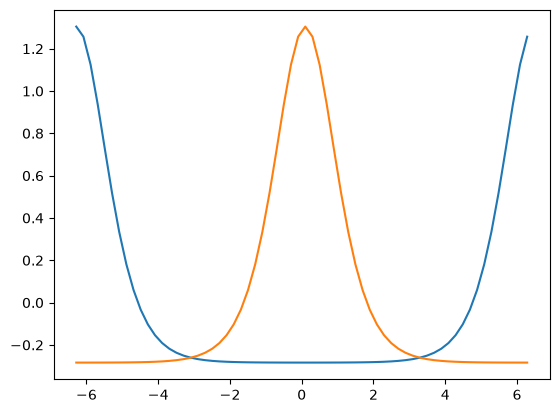

In [4]:
tw = KdVNewton(P =L, target_amp=0.5, mean=0, dx = camera.dx)
tw.solve_w_continuation()
# tw._plot_()
plt.plot(camera.x, tw.get_physical(tw.phi_hat));
plt.plot(camera.x, tw.get_physical(tw.phi_hat_mid));


For other periods we want $L = Pm$ so that m waves pass inside L

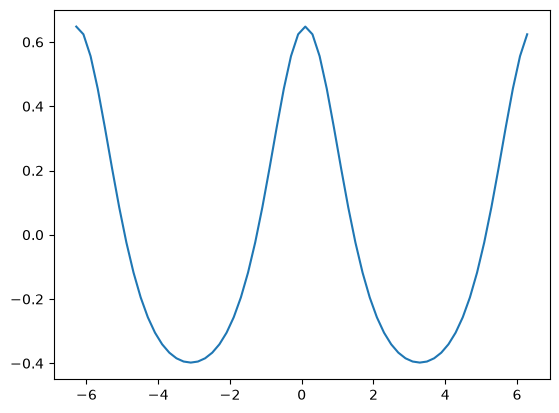

In [5]:
m = 2
P = L/m
tw2 = KdVNewton(P =P, target_amp=0.5, mean=0, dx = camera.dx)
tw2.solve_w_continuation()
# tw._plot_()
phi = tw2.get_physical(tw2.phi_hat)
phis = np.tile(phi,m) # copies the array "m" times
plt.plot(camera.x, phis );

33 17


c:\Users\henri\Documents\progging\Prosjekt_Master\.venv\Lib\site-packages\matplotlib\cbook.py:1810: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\henri\Documents\progging\Prosjekt_Master\.venv\Lib\site-packages\matplotlib\cbook.py:1407: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


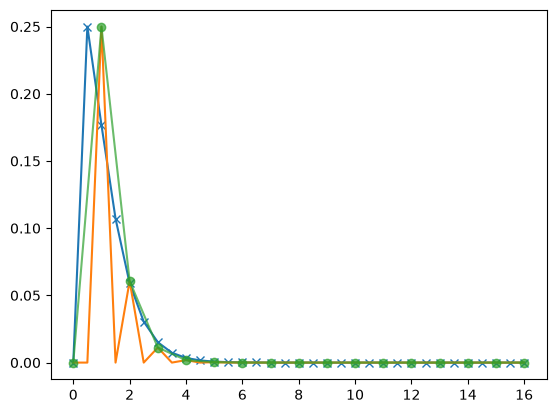

In [10]:
# I should also be allowed to plot different periods in the same spectrum:
ph1 = tw.phi_hat
ph2 = tw2.phi_hat

print(len(ph1), len(ph2))

plt.plot(tw.k, ph1, '-x')
plt.plot(tw.k, np.fft.rfft(phis)/N)
plt.plot(tw2.k,ph2, '-o', alpha =0.7)

In [12]:
# Shifing to 0
# The waves have throughs that pass y=0, however, by changing the mean - lifting the plot - we can fix these positions to 0, and so can make solitons out of data that doesn't have L=Pm, for an ineger m.
u = tw2.get_physical(tw2.phi_hat_mid)
u0 = u + np.abs(np.min(u))


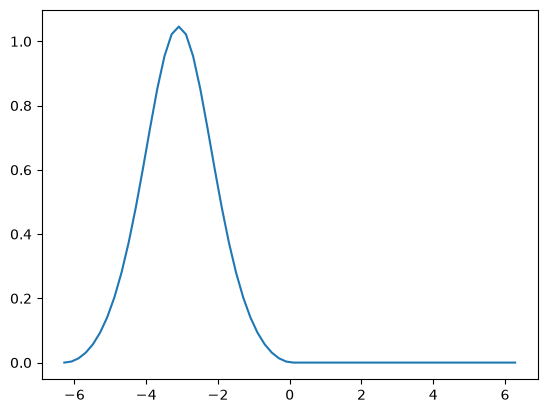

In [13]:
# plt.plot(u0) # and then

u_c = np.pad(u0, (0, N-tw2.N))

plt.plot(camera.x, u_c)
